In [1]:
# env: spaceapps
import torch
import torchvision.transforms as transforms
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [2]:
# 1. Load DINOv2 model from PyTorch Hub (Small variant: dinov2_vits14)
# Patch size is 14x14 pixels per token
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dinov2 = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14').to(device)
dinov2.eval()

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /home/luis-carlos/.cache/torch/hub/main.zip


/home/luis-carlos/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/home/luis-carlos/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/home/luis-carlos/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
0.7%

Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /home/luis-carlos/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100.0%


DinoVisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 384, kernel_size=(14, 14), stride=(14, 14))
    (norm): Identity()
  )
  (blocks): ModuleList(
    (0-11): 12 x NestedTensorBlock(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True, bias=True)
      (attn): MemEffAttention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): LayerScale()
      (drop_path1): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True, bias=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
      (ls2): LayerScale()
      (drop_path2): Identity()
    )
  )
  (norm): LayerNorm((384,), eps=1

In [3]:
# 2. Image Preprocessing
# Note: Input dimensions must be multiples of 14 (patch size)
img_height, img_width = 448, 448  # Gives a (448/14) x (448/14) = 32x32 patch grid

transform = transforms.Compose([
    transforms.Resize((img_height, img_width)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [4]:
image_path = "./data/aerial_image.png"
image = Image.open(image_path).convert("RGB")
input_tensor = transform(image).unsqueeze(0).to(device)  # Shape: (1, 3, 448, 448)

In [5]:
# 3. Extract Patch-Level Spatial Embeddings
with torch.no_grad():
    features = dinov2.forward_features(input_tensor)
    # Extract normalized patch tokens (excluding the global CLS token)
    patch_embeddings = features['x_norm_patchtokens']  # Shape: (1, 1024, 384)

In [6]:
# 4. Reshape Embeddings into Tabular Data (N_patches, Feature_Dim)
patch_embeddings = patch_embeddings.squeeze(0).cpu().numpy()  # Shape: (1024, 384)

patch_h = img_height // 14  # 32
patch_w = img_width // 14   # 32

In [8]:
print(f"Extracted {patch_embeddings.shape[0]} spatial embeddings of dimension {patch_embeddings.shape[1]}")
print(f"Feature grid shape: {patch_h} x {patch_w}")

Extracted 1024 spatial embeddings of dimension 384
Feature grid shape: 32 x 32


In [20]:
# 5. Perform K-Means Clustering on the Patch Embeddings
num_clusters = 6  # Number of visual segments/objects to group
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(patch_embeddings)  # Shape: (1024,)

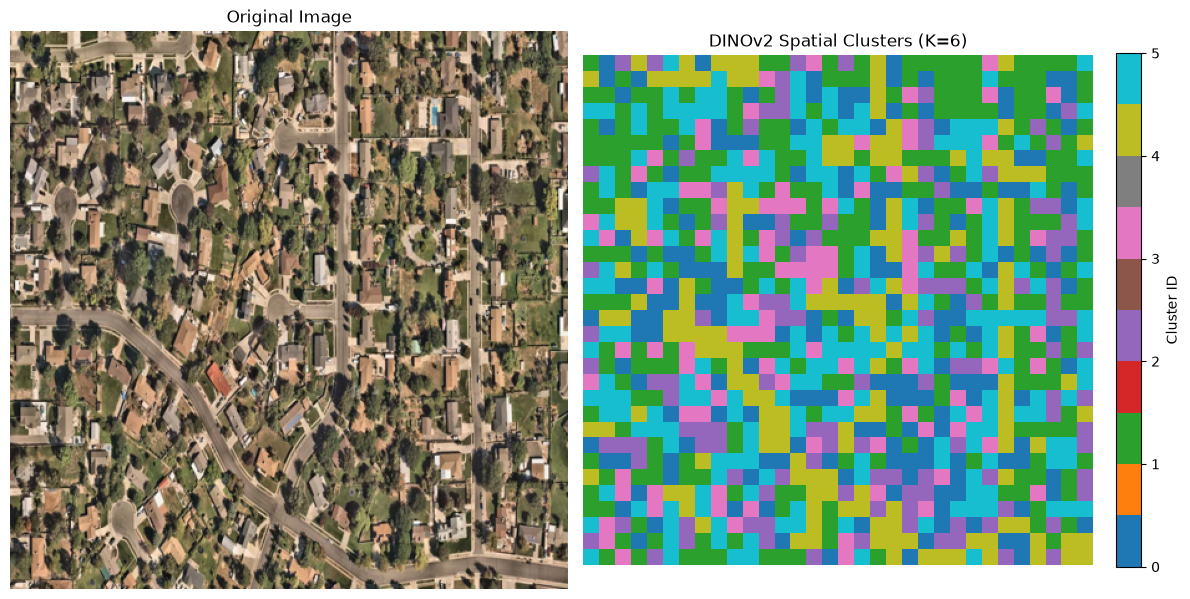

In [21]:
# Reshape labels back to 2D spatial grid (32, 32)
cluster_grid = cluster_labels.reshape(patch_h, patch_w)

# 6. Visualize Original Image alongside the Spatial Cluster Map
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(image.resize((img_width, img_height)))
axes[0].set_title("Original Image")
axes[0].axis("off")

# Display clustered segments with categorical colors
im = axes[1].imshow(cluster_grid, cmap="tab10")
axes[1].set_title(f"DINOv2 Spatial Clusters (K={num_clusters})")
axes[1].axis("off")

plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04, label="Cluster ID")
plt.tight_layout()
plt.show()